# EMG Signal Processing: Cleaning, MVC Normalization and Feature Extraction

**Muscle analysed:** left anterior deltoid (`LT ANT.DELTOID (uV)`) · **Sensor** Noraxon with sample size 2000 Hz

## What you will learn
1. What raw surface EMG looks like, and why it needs cleaning
2. How to clean it: remove offset, band-pass filter, mains notch
3. Why we normalize to an **MVC** (maximum voluntary contraction) and how to compute it
4. How to turn a long signal into **features** (MAV, RMS, waveform length, zero crossings)


## Step 1, necessary libraries

In [36]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass   # not running in Colab: use local file paths below

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, welch
from scipy.ndimage import uniform_filter1d
from numpy.lib.stride_tricks import sliding_window_view

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 2, Data loading


In [37]:
# ---- files and muscle ----
EXPERIMENTAL_FILE = "/content/drive/MyDrive/Teaching AI for human factors/EMG Updating/2026-09-17-17-44_MR_Drywall_Experiment.csv"
MVC_FILE          = "/content/drive/MyDrive/Teaching AI for human factors/EMG Updating/2026-09-17-17-22_MR_Drywall_MVC.csv"
EMG_COLUMN = "LT ANT.DELTOID (uV)" # i selected this as the participant was left dominent

# ---- cleaning ----
LOWCUT, HIGHCUT = 20, 450          # band-pass limits in Hz (surface EMG lives roughly here based on the prior work)
USE_NOTCH, NOTCH_FREQ = True, 60   # Remove 60 Hz mains hum caused by nearby electrical power sources/equipment

# ---- MVC normalization ----
MVC_WINDOW_SEC = 1.0               # MVC = highest 1-second RMS in the MVC file
MVC_TIME_RANGE_SEC = None          # e.g. (28, 38) to use only that part of the MVC file; none = whole file

# ---- features ----
WINDOW_SEC, STEP_SEC = 0.5, 0.25   # 0.5-s windows, moving forward 0.25 s each time (50% overlap)
ZC_THRESHOLD_UV = 2.0              # ignore sign changes smaller than this (noise) when counting zero crossings

# ---- plotting ----
PLOT_WINDOW_SEC = 30               # length of the example window used in the plots
RANDOM_SEED = 7

## Step 3
A Noraxon CSV has 3 information rows, then the column names, then one row per sample.
The first data row also contains the *text* "Activity", so we convert everything to numbers and drop anything that is not a valid number.

In [23]:
exp_df = pd.read_csv(EXPERIMENTAL_FILE, skiprows=3, low_memory=False)
mvc_df = pd.read_csv(MVC_FILE,          skiprows=3, low_memory=False)
exp_df.columns = exp_df.columns.str.strip()
mvc_df.columns = mvc_df.columns.str.strip()

print("Muscle channels in the file:")
for c in [c for c in exp_df.columns if "(uV)" in c]:
    print("  ", c, "  <-- selected" if c == EMG_COLUMN else "")

# Extract the time and selected EMG column as numeric arrays.
def get_signal(df, column):
    t = pd.to_numeric(df["time"], errors="coerce").to_numpy()
    x = pd.to_numeric(df[column], errors="coerce").to_numpy()
    ok = np.isfinite(t) & np.isfinite(x)     # removes the text row and any gaps
    return t[ok], x[ok]

time_exp, emg_exp = get_signal(exp_df, EMG_COLUMN)
time_mvc, emg_mvc = get_signal(mvc_df, EMG_COLUMN)

FS = int(round(1 / np.median(np.diff(time_exp))))     # just for checking purpose, sampling frequency in Hz, measured from the time column
print(f"\nSampling rate: {FS} Hz  (one sample every {1000/FS:.2f} ms)")
print(f"Experiment: {len(emg_exp):,} samples = {len(emg_exp)/FS/60:.1f} minutes")
print(f"MVC trial : {len(emg_mvc):,} samples = {len(emg_mvc)/FS:.0f} seconds")

Muscle channels in the file:
   LT ANT.DELTOID (uV)   <-- selected
   RT ANT.DELTOID (uV) 
   LT BICEPS BR. (uV) 
   RT BICEPS BR. (uV) 
   LT LUMBAR ES (uV) 
   RT LUMBAR ES (uV) 
   LT EXT.DIG. (uV) 
   RT EXT.DIG. (uV) 
   LT LAT. GASTRO (uV) 
   RT LAT. GASTRO (uV) 

Sampling rate: 2000 Hz  (one sample every 0.50 ms)
Experiment: 6,304,320 samples = 52.5 minutes
MVC trial : 250,435 samples = 125 seconds


## Step 4
**Always plot raw data before processing it.** Raw EMG oscillates around a baseline and is measured in microvolts (µV).

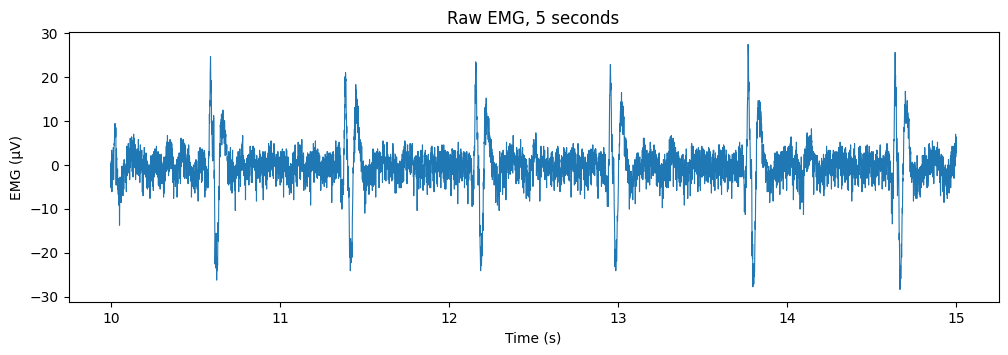

In [24]:
s = (time_exp >= 10) & (time_exp < 15) #5 second plot
plt.figure(figsize=(12, 3.5))
plt.plot(time_exp[s], emg_exp[s], lw=0.8)
plt.xlabel("Time (s)"); plt.ylabel("EMG (µV)")
plt.title("Raw EMG, 5 seconds")
plt.show()

## Step 5, Clean the signal
Three simple operations:

| Operation | Why |
|---|---|
| Subtract the mean (**DC offset**) | Centres the signal on zero |
| **Band-pass** 20–450 Hz | Removes slow drift / movement (<20 Hz) and high-frequency noise (>450 Hz); keeps the EMG band |
| **Notch** at 60 Hz | Removes mains electrical hum |

We use *zero-phase* filtering (`sosfiltfilt`, `filtfilt`), which filters forwards and backwards so the signal is not shifted in time.

In [25]:
def bandpass(x, fs, low, high, order=4):
    sos = butter(order, [low, high], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x) #  this runs in runs forwards and backwards directions

# Notch filter removes power-line noise at the chosen frequency.
# Q=30 controls how narrow the removed band is around that frequency.
def notch(x, fs, freq, Q=30):
    b, a = iirnotch(freq, Q, fs)
    return filtfilt(b, a, x)

def clean(x):
    x = x - np.mean(x)                      # 1) remove DC offset
    x = bandpass(x, FS, LOWCUT, HIGHCUT)    # 2) band-pass
    if USE_NOTCH:
        x = notch(x, FS, NOTCH_FREQ)        # 3) mains notch
    return x

exp_clean = clean(emg_exp)
mvc_clean = clean(emg_mvc)                  # the MVC trial gets EXACTLY the same cleaning
print("Cleaning done.")

Cleaning done.


## Step 6, Raw vs cleaned
We pick a random window of the recording where the muscle is working. The **spectrum** (bottom right) is where the benefit of filtering is clearest.

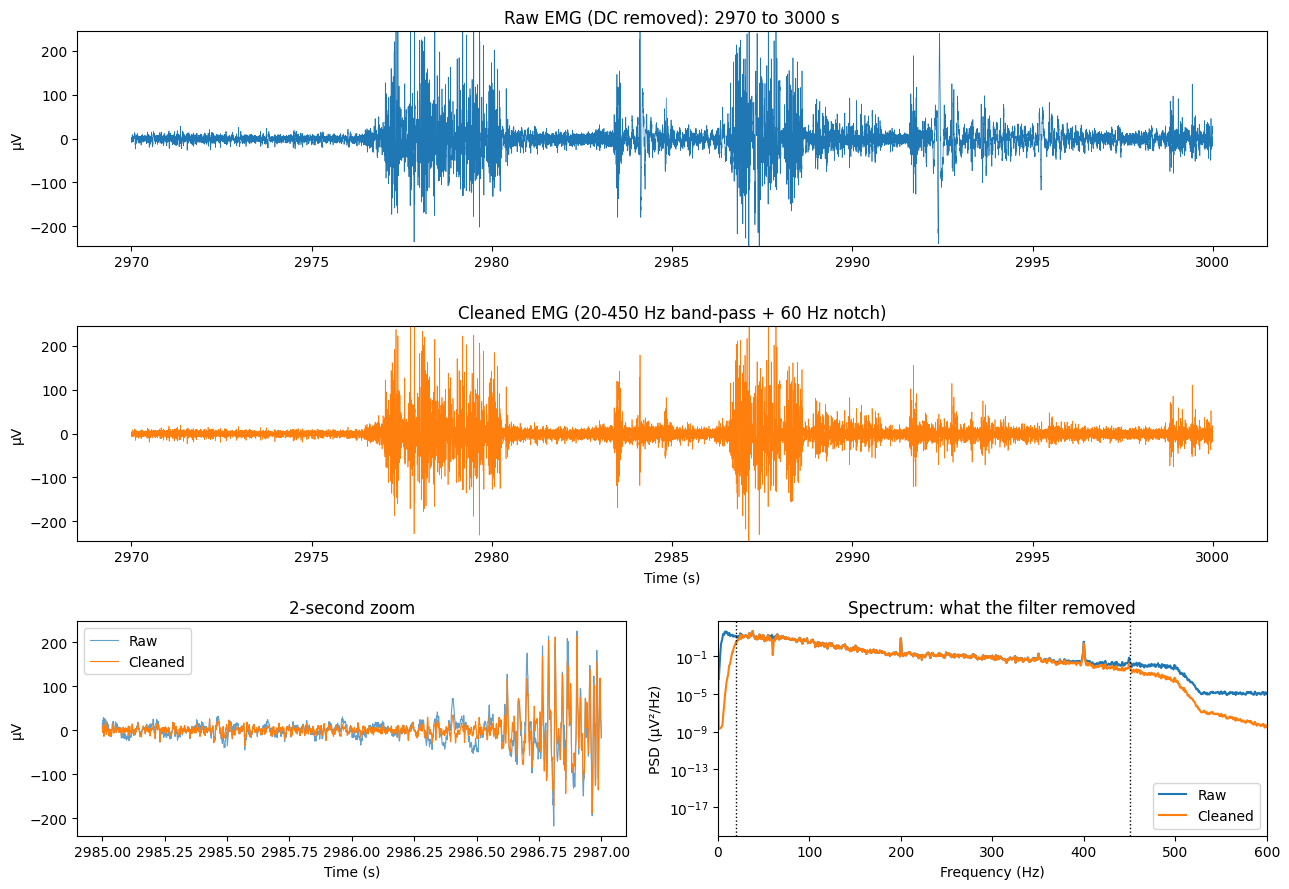

In [38]:

def moving_rms(x, fs, win_sec):

    # Convert window length from seconds to number of samples
    n = max(1, int(win_sec * fs))

    # Square the signal, average it over the moving window,
    # then take the square root to obtain RMS.
    # np.maximum(..., 0) avoids tiny negative rounding errors before the square root.
    return np.sqrt(
        np.maximum(
            uniform_filter1d(
                x ** 2,
                n,
                mode="nearest"
            ),
            0
        )
    )


def moving_mav(x, fs, win_sec):

    # Convert window length from seconds to number of samples
    n = max(1, int(win_sec * fs))

    # Take absolute EMG values and average them over the moving window
    return uniform_filter1d(
        np.abs(x),
        n,
        mode="nearest"
    )


def pick_window(env, fs, win_sec, seed):

    # Convert plotting-window duration from seconds to samples
    n = int(win_sec * fs)

    # Calculate how many complete windows fit inside the signal
    k = len(env) // n

    # Divide the envelope into non-overlapping windows
    # and calculate average activity in each window
    means = env[:k * n].reshape(k, n).mean(axis=1)

    # Keep windows whose activity is above the 60th percentile
    # so we are more likely to show a useful muscle contraction
    candidates = np.where(
        means >= np.percentile(means, 60)
    )[0]

    # Randomly select one of those relatively active windows
    # using a fixed seed so the same window is chosen each time
    i = np.random.default_rng(seed).choice(candidates)

    # Return the starting and ending sample numbers
    return i * n, (i + 1) * n


# ------------------------------------------------------------
# STEP 1 — Create an RMS envelope only for selecting a useful plot
# ------------------------------------------------------------

# Calculate a 250-ms RMS envelope from the cleaned EMG
# This represents the local activity level in µV
env_uv = moving_rms(
    exp_clean,
    FS,
    0.25
)


# ------------------------------------------------------------
# STEP 2 — Select one relatively active section of the experiment
# ------------------------------------------------------------

# Find the start and end sample of the selected plotting window
i0, i1 = pick_window(
    env_uv,
    FS,
    PLOT_WINDOW_SEC,
    RANDOM_SEED
)


# Extract the time values for the selected section
t = time_exp[i0:i1]

# Extract the raw EMG and remove its DC offset
raw = emg_exp[i0:i1] - emg_exp.mean()

# Extract the corresponding cleaned EMG
cln = exp_clean[i0:i1]


# ------------------------------------------------------------
# STEP 3 — Set a common y-axis range for raw and cleaned signals
# ------------------------------------------------------------

# Use the 99.9th percentile instead of the absolute maximum
# so one extreme spike does not make the whole graph look compressed
lim = np.percentile(
    np.abs(raw),
    99.9
)


# ------------------------------------------------------------
# STEP 4 — Create the figure layout
# ------------------------------------------------------------

# Create one figure with 3 rows and 2 columns
fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(3, 2)


# ------------------------------------------------------------
# Plot 1 — Raw EMG
# ------------------------------------------------------------

# First plot spans both columns in the first row
ax1 = fig.add_subplot(gs[0, :])

# Plot raw EMG
ax1.plot(
    t,
    raw,
    lw=0.5
)

# Add title showing the selected time range
ax1.set_title(
    f"Raw EMG (DC removed): {t[0]:.0f} to {t[-1]:.0f} s"
)


# ------------------------------------------------------------
# Plot 2 — Cleaned EMG
# ------------------------------------------------------------

# Second plot spans both columns and shares the same x-axis
ax2 = fig.add_subplot(
    gs[1, :],
    sharex=ax1
)

# Plot the filtered EMG
ax2.plot(
    t,
    cln,
    lw=0.5,
    color="C1"
)

# Show the filters used in the title
ax2.set_title(
    f"Cleaned EMG ({LOWCUT}-{HIGHCUT} Hz band-pass"
    + (
        f" + {NOTCH_FREQ} Hz notch)"
        if USE_NOTCH
        else ")"
    )
)


# Give raw and cleaned plots the same y-axis range
# so students can compare them fairly
for a in (ax1, ax2):
    a.set_ylim(-lim, lim)
    a.set_ylabel("µV")

# Label the x-axis
ax2.set_xlabel("Time (s)")


# ------------------------------------------------------------
# STEP 5 — Create a 2-second zoomed section
# ------------------------------------------------------------

# Choose the middle of the selected plotting window
z0 = t[0] + PLOT_WINDOW_SEC / 2

# Select only 2 seconds starting from that point
z = (
    (t >= z0)
    & (t < z0 + 2)
)


# Create the zoom plot
ax3 = fig.add_subplot(gs[2, 0])

# Plot raw EMG in the 2-second section
ax3.plot(
    t[z],
    raw[z],
    lw=0.8,
    alpha=0.7,
    label="Raw"
)

# Plot cleaned EMG over the same 2-second section
ax3.plot(
    t[z],
    cln[z],
    lw=0.8,
    label="Cleaned"
)

# Add labels and title
ax3.set_title("2-second zoom")
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("µV")
ax3.legend()


# ------------------------------------------------------------
# STEP 6 — Compare frequency content before and after cleaning
# ------------------------------------------------------------

# Calculate the power spectrum of the raw EMG
f1, p1 = welch(
    raw,
    fs=FS,
    nperseg=2 * FS
)

# Calculate the power spectrum of the cleaned EMG
f2, p2 = welch(
    cln,
    fs=FS,
    nperseg=2 * FS
)


# Create the frequency-spectrum plot
ax4 = fig.add_subplot(gs[2, 1])

# Plot raw EMG power spectrum
ax4.semilogy(
    f1,
    p1,
    label="Raw"
)

# Plot cleaned EMG power spectrum
ax4.semilogy(
    f2,
    p2,
    label="Cleaned"
)


# Mark the lower band-pass cutoff frequency
ax4.axvline(
    LOWCUT,
    color="k",
    ls=":",
    lw=1
)

# Mark the upper band-pass cutoff frequency
ax4.axvline(
    HIGHCUT,
    color="k",
    ls=":",
    lw=1
)


# Show frequencies from 0 to 600 Hz
ax4.set_xlim(0, 600)

# Add title and labels
ax4.set_title(
    "Spectrum: what the filter removed"
)
ax4.set_xlabel("Frequency (Hz)")
ax4.set_ylabel("PSD (µV²/Hz)")
ax4.legend()


# Adjust spacing so plots do not overlap
plt.tight_layout()

# Display the figure
plt.show()

filtering rarely changes the *shape* of the muscle signal much. It removes what should not be there: slow drift, out-of-band noise and mains hum. Look at the spectrum: the cleaned line falls away outside the 20–450 Hz band.

## Step 7, Full pipeline of cleaning


The **filtered EMG is still supposed to look fast and noisy** because EMG is a rapidly oscillating electrical signal.  
To obtain a visually clean muscle-activation signal, we then:

1. **Rectify** the filtered EMG: make negative values positive.
2. Calculate a **moving RMS envelope**.
3. The RMS envelope is the smooth processed signal that represents the changing level of muscle activation.



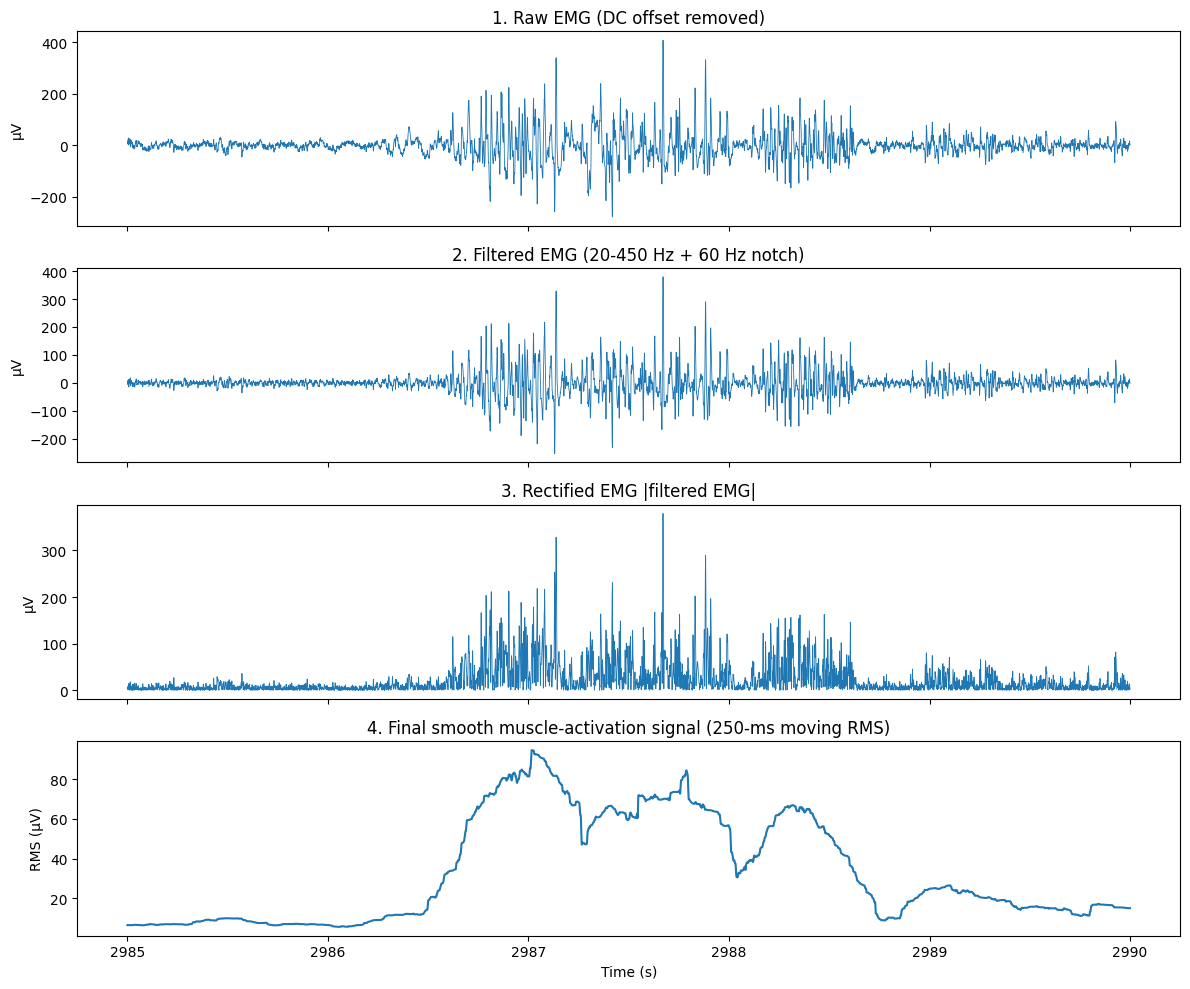

In [26]:
# STEP 7 — Visualize the complete EMG processing pipeline

# Use a 5-second portion of the same selected example window
SHOW_SEC = 5

show_mask = (
    (t >= z0)
    & (t < z0 + SHOW_SEC)
)

tt = t[show_mask]

# Raw signal from the same time segment (DC offset removed)
raw_segment = raw[show_mask]

# Band-pass + notch filtered EMG
filtered_segment = cln[show_mask]

# Rectified EMG: negative values become positive
rectified_segment = np.abs(filtered_segment)

# Smooth RMS envelope: represents muscle activation level
RMS_ENVELOPE_SEC = 0.25
rms_envelope_segment = moving_rms(
    filtered_segment,
    FS,
    RMS_ENVELOPE_SEC
)

fig, ax = plt.subplots(
    4,
    1,
    figsize=(12, 10),
    sharex=True
)

# 1. Raw
ax[0].plot(
    tt,
    raw_segment,
    lw=0.6
)
ax[0].set_title("1. Raw EMG (DC offset removed)")
ax[0].set_ylabel("µV")

# 2. Filtered
ax[1].plot(
    tt,
    filtered_segment,
    lw=0.6
)
ax[1].set_title(
    f"2. Filtered EMG ({LOWCUT}-{HIGHCUT} Hz"
    + (f" + {NOTCH_FREQ} Hz notch)" if USE_NOTCH else ")")
)
ax[1].set_ylabel("µV")

# 3. Rectified
ax[2].plot(
    tt,
    rectified_segment,
    lw=0.6
)
ax[2].set_title("3. Rectified EMG |filtered EMG|")
ax[2].set_ylabel("µV")

# 4. Smooth processed signal
ax[3].plot(
    tt,
    rms_envelope_segment,
    lw=1.5
)
ax[3].set_title(
    f"4. Final smooth muscle-activation signal "
    f"({RMS_ENVELOPE_SEC*1000:.0f}-ms moving RMS)"
)
ax[3].set_ylabel("RMS (µV)")
ax[3].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()


## Step 8, MVC reference
A raw value like "40 µV" is hard to compare between people, muscles, days or electrode placements. So we express activity as a **percentage of the muscle's maximum voluntary contraction (MVC)**.

**Rule used here:** MVC reference = the **highest 1-second moving RMS** in the MVC recording (cleaned the same way).

*why not the single max calue from file?* One spike could define "100 %", and a single-sample peak is a different kind of number from the RMS values we compare it with.

The MVC file contains several efforts (different muscles/tasks). The code takes the highest value for the selected muscle; **confirm the printed time matches the left-deltoid effort**, or set `MVC_TIME_RANGE_SEC` in Step 2.

MVC reference: RMS = 419.5 µV | MAV = 327.6 µV | reached at t = 34.9 s


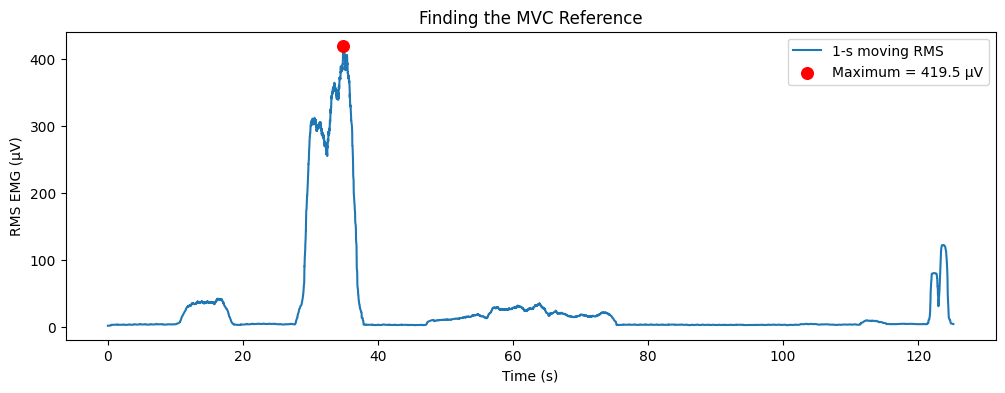

In [27]:
# MVC = highest sustained processed EMG amplitude over the selected window

sel = np.ones(len(mvc_clean), dtype=bool)

if MVC_TIME_RANGE_SEC is not None:
    sel = (
        (time_mvc >= MVC_TIME_RANGE_SEC[0])
        & (time_mvc <= MVC_TIME_RANGE_SEC[1])
    )

assert sel.any(), "No MVC samples in MVC_TIME_RANGE_SEC"


# Calculate 1-second moving RMS and MAV
mvc_rms_env = moving_rms(
    mvc_clean,
    FS,
    MVC_WINDOW_SEC
)

mvc_mav_env = moving_mav(
    mvc_clean,
    FS,
    MVC_WINDOW_SEC
)


# Selected MVC region
idx = np.where(sel)[0]


# Highest sustained values
MVC_RMS_REF = mvc_rms_env[idx].max()
MVC_MAV_REF = mvc_mav_env[idx].max()


# Find when the maximum RMS occurred
peak_index = idx[np.argmax(mvc_rms_env[idx])]
peak_t = time_mvc[peak_index]


print(
    f"MVC reference: "
    f"RMS = {MVC_RMS_REF:.1f} µV | "
    f"MAV = {MVC_MAV_REF:.1f} µV | "
    f"reached at t = {peak_t:.1f} s"
)


plt.figure(figsize=(12, 4))

plt.plot(
    time_mvc,
    mvc_rms_env,
    label=f"{MVC_WINDOW_SEC:g}-s moving RMS"
)

# Mark only the actual maximum point
plt.scatter(
    peak_t,
    MVC_RMS_REF,
    color="red",
    s=70,
    zorder=5,
    label=f"Maximum = {MVC_RMS_REF:.1f} µV"
)

plt.xlabel("Time (s)")
plt.ylabel("RMS EMG (µV)")
plt.title("Finding the MVC Reference")
plt.legend()
plt.show()

Quality check: find and remove artifact spikes. A sample in the experiment larger than anything the muscle produced during its maximal effort is probably a glitch, such as a bumped electrode or cable. The next three cells find such samples, plot them and compare all channels at that moment (a ratio well above 1 means unusually large for that channel), and remove 0.75 s on each side. In this recording there was one event at about 1191 s, only the left deltoid was abnormal (ratio 8.9, others ≤ 0.7), and 1.5 s (0.05 % of the recording) was removed.

In [28]:
# find implausible spikes (a sample bigger than anything seen during the maximal effort)
PAD_SEC = 0.75                                   # remove this many seconds on each side of a spike
MVC_PEAK_UV = np.abs(mvc_clean[idx]).max()       # biggest sample during the MVC effort
big = np.where(np.abs(exp_clean) > MVC_PEAK_UV)[0]
events = []
if len(big):
    for g in np.split(big, np.where(np.diff(big) > 0.5 * FS)[0] + 1):
        k = g[np.argmax(np.abs(exp_clean[g]))]
        events.append(time_exp[k])
        print(f"event at {time_exp[k]:.2f} s, peak {exp_clean[k]:.0f} µV")
print("MVC peak:", round(MVC_PEAK_UV), "µV | number of events:", len(events))

event at 1190.96 s, peak -2421 µV
MVC peak: 1550 µV | number of events: 1


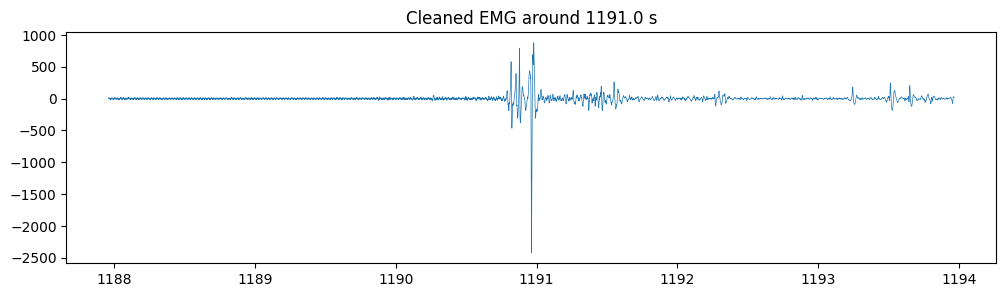

LT ANT.DELTOID (uV)    peak  2569.1 µV   ratio   8.9
RT ANT.DELTOID (uV)    peak    11.6 µV   ratio   0.1
LT BICEPS BR. (uV)     peak    60.5 µV   ratio   0.0
RT BICEPS BR. (uV)     peak     9.4 µV   ratio   0.1
LT LUMBAR ES (uV)      peak    38.8 µV   ratio   0.4
RT LUMBAR ES (uV)      peak    40.6 µV   ratio   0.7
LT EXT.DIG. (uV)       peak    84.9 µV   ratio   0.4
RT EXT.DIG. (uV)       peak    21.4 µV   ratio   0.2
LT LAT. GASTRO (uV)    peak    11.3 µV   ratio   0.0
RT LAT. GASTRO (uV)    peak    25.0 µV   ratio   0.3


In [29]:
# look at each event and compare all channels at that moment
channels = [c for c in exp_df.columns if "(uV)" in c]
t_all = pd.to_numeric(exp_df["time"], errors="coerce").to_numpy()
for te in events[:3]:
    m = (time_exp >= te - 3) & (time_exp <= te + 3)
    plt.figure(figsize=(12, 3)); plt.plot(time_exp[m], exp_clean[m], lw=0.5)
    plt.title(f"Cleaned EMG around {te:.1f} s"); plt.show()
    w = (t_all >= te - 0.5) & (t_all <= te + 0.5)
    for c in channels:
        x = pd.to_numeric(exp_df[c], errors="coerce").to_numpy()
        typical = np.nanpercentile(np.abs(x[::10] - np.nanmean(x)), 99.9)   # channel's own normal peak
        peak = np.nanmax(np.abs(x[w] - np.nanmean(x[w])))
        print(f"{c:22s} peak {peak:7.1f} µV   ratio {peak / typical:5.1f}")

Removed 3001 samples = 1.50 s of 52.5 min


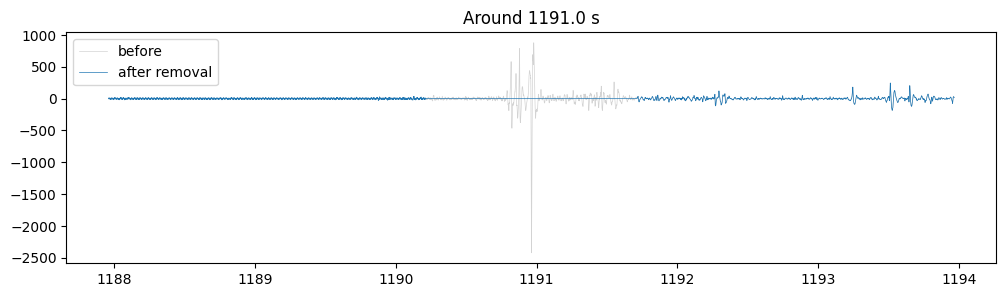

In [30]:
# remove the artifact segments from the cleaned signal
exp_clean_before_removal = exp_clean.copy()                 # keep the original so we can compare
artifact_mask = np.zeros(len(exp_clean), dtype=bool)        # True = this sample was removed
for te in events:
    artifact_mask |= (time_exp >= te - PAD_SEC) & (time_exp <= te + PAD_SEC)
exp_clean[artifact_mask] = 0                                # removed samples set to 0 and tracked in artifact_mask
print(f"Removed {artifact_mask.sum()} samples = {artifact_mask.sum() / FS:.2f} s of {len(exp_clean) / FS / 60:.1f} min")
for te in events[:3]:
    m = (time_exp >= te - 3) & (time_exp <= te + 3)
    plt.figure(figsize=(12, 3))
    plt.plot(time_exp[m], exp_clean_before_removal[m], color="lightgray", lw=0.5, label="before")
    plt.plot(time_exp[m], exp_clean[m], lw=0.5, label="after removal")
    plt.title(f"Around {te:.1f} s"); plt.legend(); plt.show()

In [31]:
#VERIFYING THE RESULT
exp_rms_1s = moving_rms(
    exp_clean,
    FS,
    1.0
)

max_exp_rms = np.max(exp_rms_1s)

print("MVC RMS reference:", MVC_RMS_REF)
print("Maximum experimental 1-s RMS:", max_exp_rms)

print(
    "Maximum experimental %MVC:",
    max_exp_rms / MVC_RMS_REF * 100
)

MVC RMS reference: 419.4748482434483
Maximum experimental 1-s RMS: 228.32983630611093
Maximum experimental %MVC: 54.43230679079867


## Step 9, Normalize the processed muscle-activation signal to %MVC

We normalize the **RMS envelope**, not the fast positive/negative waveform.

This gives a smooth signal that is easy to interpret:

- 25 = 25% MVC
- 50 = 50% MVC
- 100 = 100% MVC


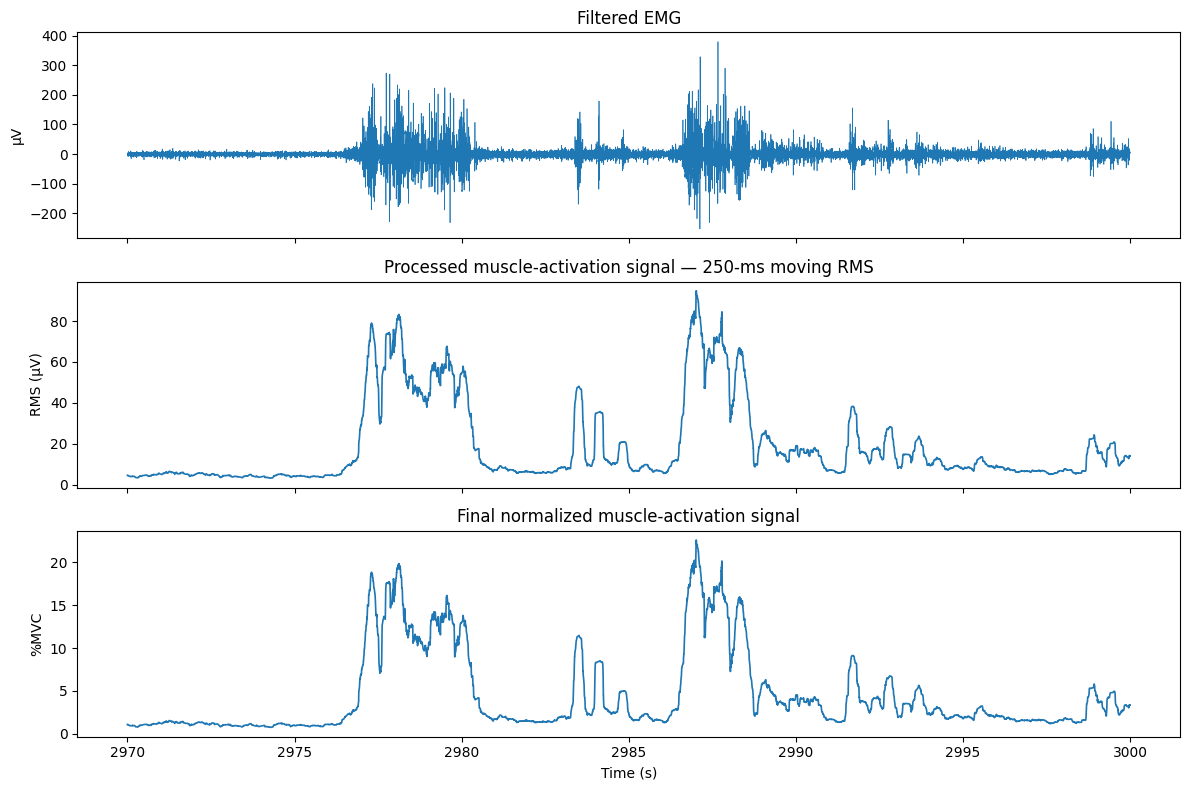

In [32]:
# STEP 9 — Convert the RMS envelope to %MVC

# 250-ms moving RMS for the whole experimental session
env_uv = moving_rms(
    exp_clean,
    FS,
    0.25
)

# Normalize the smooth RMS envelope to the MVC reference
env_pct = (
    env_uv
    / MVC_RMS_REF
    * 100
)

fig, ax = plt.subplots(
    3,
    1,
    figsize=(12, 8),
    sharex=True
)

# Filtered bipolar EMG
ax[0].plot(
    t,
    cln,
    lw=0.5
)
ax[0].set_ylabel("µV")
ax[0].set_title("Filtered EMG")

# Smooth RMS envelope
ax[1].plot(
    t,
    env_uv[i0:i1],
    lw=1.2
)
ax[1].set_ylabel("RMS (µV)")
ax[1].set_title("Processed muscle-activation signal — 250-ms moving RMS")

# Normalized smooth envelope
ax[2].plot(
    t,
    env_pct[i0:i1],
    lw=1.2
)
ax[2].set_ylabel("%MVC")
ax[2].set_title("Final normalized muscle-activation signal")
ax[2].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()


## Step 10, Time-domain features
We cut the cleaned signal into **0.5 s windows** (moving 0.25 s each time, so neighbouring windows overlap by 50 %) and describe each window with a few numbers:

| Feature | Meaning |
|---|---|
| **MAV** | mean of the absolute values: average amplitude |
| **RMS** | root mean square: amplitude (related to signal power) |
| **Waveform length** | total up-and-down travel of the signal: amplitude + frequency + complexity |
| **Zero crossings** | how often the signal crosses zero (rough frequency); tiny crossings below `ZC_THRESHOLD_UV` are ignored as noise |

In [33]:
def extract_features(windows, zc_thr):
    mav = np.mean(np.abs(windows), axis=1)
    rms = np.sqrt(np.mean(windows ** 2, axis=1))
    wl  = np.sum(np.abs(np.diff(windows, axis=1)), axis=1)
    a, b = windows[:, :-1], windows[:, 1:]
    zc  = np.sum((a * b < 0) & (np.abs(a - b) >= zc_thr), axis=1)
    return pd.DataFrame({"MAV_uV": mav, "RMS_uV": rms, "Waveform_Length": wl, "Zero_Crossings": zc})

win, step = int(WINDOW_SEC * FS), int(STEP_SEC * FS)
print("Samples per window:", win, "| samples per step:", step)

windows = sliding_window_view(exp_clean, win)[::step]      # one row per window
starts  = np.arange(0, len(exp_clean) - win + 1, step)

features = extract_features(windows, ZC_THRESHOLD_UV)
features["RMS_percent_MVC"] = features["RMS_uV"] / MVC_RMS_REF * 100
features["MAV_percent_MVC"] = features["MAV_uV"] / MVC_MAV_REF * 100
features["window_start_sec"] = time_exp[starts]
features["window_end_sec"]   = time_exp[starts + win - 1]
features.head(10)

Samples per window: 1000 | samples per step: 500


,MAV_uV,RMS_uV,Waveform_Length,Zero_Crossings,RMS_percent_MVC,MAV_percent_MVC,window_start_sec,window_end_sec
0,3.500028,4.711783,1501.728649,74,1.123258,1.068410,0.00,0.4995
1,3.709802,4.916751,1463.571714,74,1.172121,1.132445,0.25,0.7495
2,3.233427,4.142625,1316.119848,58,0.987574,0.987028,0.50,0.9995
3,3.347529,4.470976,1353.614649,60,1.065851,1.021858,0.75,1.2495
4,3.076276,4.163586,1334.235578,65,0.992571,0.939056,1.00,1.4995
5,2.233883,2.855831,1217.232750,70,0.680811,0.681910,1.25,1.7495
6,2.521555,3.487357,1205.561818,72,0.831363,0.769723,1.50,1.9995
7,2.563029,3.537169,1199.072480,65,0.843237,0.782384,1.75,2.2495
8,1.890321,2.416124,1143.013704,65,0.575988,0.577035,2.00,2.4995
9,3.015514,4.417617,1297.048511,57,1.053130,0.920508,2.25,2.7495


In [34]:
# windows that touch removed samples cannot be trusted -> their features are set to NaN (empty)
bad = sliding_window_view(artifact_mask, win)[::step].any(axis=1)
cols = ["MAV_uV", "RMS_uV", "Waveform_Length", "Zero_Crossings", "RMS_percent_MVC", "MAV_percent_MVC"]
features["artifact_flag"] = bad
features.loc[bad, cols] = np.nan
print("Windows excluded:", bad.sum(), "of", len(features))
print("Highest RMS %MVC:", round(features["RMS_percent_MVC"].max(), 1))

Windows excluded: 8 of 12607
Highest RMS %MVC: 64.9


## Step 11 save features

In [35]:
features.to_csv("EMG_time_domain_features.csv", index=False)
print("Saved: EMG_time_domain_features.csv", features.shape)

Saved: EMG_time_domain_features.csv (12607, 9)
